# Modelación como Movimiento Browniano Geométrico y valoración de opciones europeas

**Proyecto Final — Cálculo Estocástico (Freddy H. Marín, Universidad EAFIT)**

Este notebook replica, de forma **genérica para cualquier activo financiero**, el
procedimiento completo del enunciado:

1. Carga y limpieza de la serie de precios.
2. Validación estadística de los supuestos del **Movimiento Browniano Geométrico (MBG)**.
3. Estimación de los parámetros $\hat\mu$ y $\hat\sigma$.
4. Pronóstico **dentro de muestra** (in-sample) con **10.000 simulaciones** y métricas de ajuste (se espera **MAPE < 5 %**).
5. Pronóstico **fuera de muestra** (out-of-sample) con **10.000 simulaciones** y extracción de 5 *strikes* por cada $T$.
6. Valoración de **opciones Call europeas** (Puts como control) con cuatro métodos: **Black-Scholes**, **Monte Carlo**, **Árbol binomial CRR** y **Diferencias finitas explícitas**, para $T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$.

**Modelo.** Bajo el MBG el precio satisface la EDE
$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t \;\Longrightarrow\; r_t=\ln\frac{S_t}{S_{t-1}}\ \overset{iid}{\sim}\ N\!\Big(\big(\mu-\tfrac{\sigma^2}{2}\big)\Delta t,\ \sigma^2\Delta t\Big).$$

| # | Condición | Pruebas (H0 = se cumple) |
|---|---|---|
| C1 | Normalidad de $r_t$ | Jarque-Bera, Shapiro-Wilk (+ D'Agostino, QQ-plot) |
| C2 | Independencia | Ljung-Box, test de rachas, ACF |
| C3 | Varianza constante | Ljung-Box sobre $r_t^2$, ARCH-LM |
| C4 | Parámetros estables | t-test, Levene, KS entre mitades |
| C5 | Ajuste global | Simulación Monte Carlo |

**Parámetros fijos del enunciado:** $r=0.05$, $S_0=$ último dato de la serie,
$\sigma=$ volatilidad histórica estimada, 10.000 simulaciones,
$T=\{1,\,1/2,\,1/3,\,1/4\}$ y 5 strikes por $T$ (percentiles 10/25/50/75/90 de $S_T$
simulado fuera de muestra). Se usa la **solución exacta del MBG bajo medida
riesgo-neutral** (no el esquema de Euler), como recomiendan los apuntes.


## 1. Librerías

In [4]:
# pip install pandas matplotlib scipy

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 2. Parámetros y funciones configurables

**Todo lo modificable está aquí.** Cambie la ruta del CSV, las constantes del
enunciado o cualquier función auxiliar sin tener que buscar en el resto del
notebook.

El CSV debe tener el formato `date,<nombre_activo>` (también se admite
`observation_date` como columna de fecha). El nombre del activo se extrae
automáticamente del encabezado de la segunda columna y se guarda en `ASSET_NAME`.


In [ ]:
# ===================================================================
# 2.1  PARÁMETROS MODIFICABLES
# ===================================================================
# ---- Datos ----
DATA_DIR  = "data"                 # carpeta con los CSV

# ---- Datos ----
DATA_DIR = "data"

# Lista de activos disponibles (cambia solo el índice para correr otro)
CSV_LIST = [
    "AAPL_US_Equity.csv",       # 0
    "BCOM_Index.csv",           # 1
    "CAFEBOGO_Index.csv",       # 2
    "CIB_US_Equity.csv",        # 3
    "COP_REGN_Curncy.csv",      # 4
    "DEXCAUS.csv",              # 5
    "EC_US_Equity.csv",         # 6
    "ECOPETL_CX_Equity.csv",    # 7
    "EUCRBRDT_Index.csv",       # 8
    "EUR_Curncy.csv",           # 9
    "MSFT_US_Equity.csv",       # 10
    "NDX_Index.csv",            # 11
    "NU_US_Equity.csv",         # 12
    "SPGSEN_Index.csv",         # 13
    "SPX_Index.csv",            # 14
    "USCRWTIM_Index.csv"        # 15
]

CSV_INDEX = 6                  # <-- cambie aquí el activo a analizar
CSV_NAME  = CSV_LIST[CSV_INDEX]
CSV_PATH  = os.path.join(DATA_DIR, CSV_NAME)

DATE_CANDIDATES = ["date", "observation_date", "Date", "Fecha"]  # posibles nombres de la col. de fecha

# ---- Convenciones temporales ----
PPY   = 252                        # periodos por año (datos diarios de mercado)
dt    = 1 / PPY                    # paso temporal en años
ALPHA = 0.05                       # nivel de significancia de las pruebas

# ---- Simulación ----
N_SIM     = 10_000                 # simulaciones (in-sample y out-of-sample) — exigido por el enunciado
N_PATHS_C5 = 5_000                 # trayectorias para el chequeo visual C5
SEED      = 2026                   # semilla global de reproducibilidad

# ---- Valoración de opciones (parámetros fijos del enunciado) ----
r_free  = 0.05                     # tasa libre de riesgo (ENUNCIADO: r = 0.05)
q_yield = 0.00                     # rendimiento continuo (0 = Black-Scholes clásico; >0 = Garman-Kohlhagen)
T_LIST  = [1, 1/2, 1/3, 1/4]       # vencimientos (años)
PCTS    = [10, 25, 50, 75, 90]     # percentiles de S_T simulado -> 5 strikes por T
N_BIN   = 1000                     # pasos del árbol binomial CRR
NH_FD   = 300                      # nodos a cada lado de S0 en la malla de diferencias finitas
PRICE_DECIMALS = 4                 # redondeo de precios/strikes (recomendación del profesor)

# Tipos de opción a valorar: el enunciado prioriza Calls; "put" queda como control.
OPTION_KINDS = ["call", "put"]

np.random.seed(42)                 # para las celdas que usan el estado global de numpy

In [146]:
# ===================================================================
# 2.2  FUNCIONES AUXILIARES
# ===================================================================

# ---------- Carga genérica ----------
def load_series(csv_path, date_candidates=DATE_CANDIDATES):
    """Lee un CSV date,<activo>, detecta la columna de fecha y extrae ASSET_NAME.

    Devuelve (S, asset_name) donde S es una Serie de precios indexada por fecha.
    """
    raw = pd.read_csv(csv_path)
    # Detectar columna de fecha
    date_col = next((c for c in raw.columns if c in date_candidates), raw.columns[0])
    # El activo es la primera columna que no es la de fecha
    asset_col = next(c for c in raw.columns if c != date_col)
    raw[date_col] = pd.to_datetime(raw[date_col])
    raw[asset_col] = pd.to_numeric(raw[asset_col], errors="coerce")  # feriados/celdas vacías -> NaN
    s = (raw.set_index(date_col)[asset_col]
            .sort_index()
            .dropna())
    s.index.name = "Date"
    s.name = asset_col
    return s, asset_col


# ---------- Pruebas estadísticas (numpy/scipy, sin statsmodels) ----------
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x); den = np.sum(x**2)
    return np.array([np.sum(x[k:] * x[:len(x) - k]) / den for k in range(1, nlags + 1)])

def ljung_box(x, lags):
    x = np.asarray(x); m = len(x); rho = acf(x, lags)
    Q = m * (m + 2) * np.sum(rho**2 / (m - np.arange(1, lags + 1)))
    return Q, stats.chi2.sf(Q, lags)

def runs_test(x):
    s = np.asarray(x) > np.median(x); n1, n2 = s.sum(), (~s).sum()
    runs = 1 + np.sum(s[1:] != s[:-1])
    mu_r = 2 * n1 * n2 / (n1 + n2) + 1
    var_r = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / ((n1 + n2)**2 * (n1 + n2 - 1))
    z = (runs - mu_r) / np.sqrt(var_r)
    return z, 2 * stats.norm.sf(abs(z))

def arch_lm(x, q=5):
    e2 = (np.asarray(x) - np.mean(x))**2; y = e2[q:]
    X = np.column_stack([np.ones(len(y))] + [e2[q - i: len(e2) - i] for i in range(1, q + 1)])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    R2 = 1 - np.sum((y - X @ b)**2) / np.sum((y - y.mean())**2)
    LM = len(y) * R2
    return LM, stats.chi2.sf(LM, q)

def battery(x):
    """Batería de 9 pruebas de los supuestos del MBG. Devuelve dict de p-valores."""
    x = np.asarray(x); h = len(x) // 2
    return {
        "C1 Jarque-Bera":        stats.jarque_bera(x)[1],
        "C1 Shapiro-Wilk":       stats.shapiro(x)[1],
        "C2 Ljung-Box r (10)":   ljung_box(x, 10)[1],
        "C2 Test de rachas":     runs_test(x)[1],
        "C3 Ljung-Box r2 (10)":  ljung_box(x**2, 10)[1],
        "C3 ARCH-LM (5)":        arch_lm(x, 5)[1],
        "C4 t-test medias":      stats.ttest_ind(x[:h], x[h:], equal_var=False)[1],
        "C4 Levene varianzas":   stats.levene(x[:h], x[h:])[1],
        "C4 KS 2 muestras":      stats.ks_2samp(x[:h], x[h:])[1],
    }


# ---------- Métricas de pronóstico ----------
def point_metrics(y, yhat, y_naive):
    e = y - yhat
    return {
        "Sesgo ME (obs - pron.)": e.mean(),
        "MAE": np.abs(e).mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "MAPE (%)": 100 * np.mean(np.abs(e / y)),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(yhat))),
        "R2": 1 - (e**2).sum() / ((y - y.mean())**2).sum(),
        "Correlacion": np.corrcoef(y, yhat)[0, 1] if np.std(yhat) > 0 else np.nan,
        "Theil U (vs. ingenuo)": np.sqrt((e**2).mean()) / np.sqrt(((y - y_naive)**2).mean()),
    }

def prob_metrics(y, X):
    """Métricas de calibración de la distribución simulada. X:(N_SIM,T), y:(T,)."""
    lo95, hi95 = np.percentile(X, [2.5, 97.5], axis=0)
    lo50, hi50 = np.percentile(X, [25, 75], axis=0)
    N = X.shape[0]
    Xs = np.sort(X, axis=0); i = np.arange(1, N + 1)[:, None]
    mean_abs_diff = (2 / N**2) * ((2 * i - N - 1) * Xs).sum(axis=0)   # E|X - X'|
    crps = np.mean(np.abs(X - y).mean(axis=0) - 0.5 * mean_abs_diff)
    pit = (X < y).mean(axis=0)
    return {
        "Cobertura IC 50 % (nominal 50 %)": np.mean((y >= lo50) & (y <= hi50)),
        "Cobertura IC 95 % (nominal 95 %)": np.mean((y >= lo95) & (y <= hi95)),
        "Ancho medio IC 95 %": np.mean(hi95 - lo95),
        "CRPS medio": crps,
        "KS uniformidad PIT (p-valor)": stats.kstest(pit, "uniform")[1],
    }, pit


# ---------- Métodos de valoración de opciones ----------
def bs_price(S0, K, T, r, q, sig, kind):
    """Black-Scholes cerrado (q=0 -> BS clásico; q>0 -> Garman-Kohlhagen)."""
    d1 = (np.log(S0 / K) + (r - q + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if kind == "call":
        return S0 * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d2)
    return K * np.exp(-r * T) * stats.norm.cdf(-d2) - S0 * np.exp(-q * T) * stats.norm.cdf(-d1)

def mc_price(S0, K, T, r, q, sig, Zhalf, kind):
    """Monte Carlo riesgo-neutral con solución EXACTA del MBG + variables antitéticas.

    S_T = S0 * exp((r - q - sig^2/2) T + sig sqrt(T) Z).  Devuelve (precio, error estándar).
    """
    def payoff(Z):
        ST = S0 * np.exp((r - q - 0.5 * sig**2) * T + sig * np.sqrt(T) * Z)
        return np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    pair = 0.5 * (payoff(Zhalf) + payoff(-Zhalf)) * np.exp(-r * T)
    return pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair))

def binomial_crr(S0, K, T, r, q, sig, kind, N=N_BIN):
    """Árbol binomial Cox-Ross-Rubinstein con N pasos (inducción hacia atrás)."""
    dt_ = T / N; u = np.exp(sig * np.sqrt(dt_)); d = 1 / u
    p = (np.exp((r - q) * dt_) - d) / (u - d); disc = np.exp(-r * dt_)
    assert 0 < p < 1, "Probabilidad riesgo-neutral fuera de (0,1): reduzca dt_"
    j = np.arange(N + 1); ST = S0 * u**j * d**(N - j)
    V = np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    for _ in range(N):
        V = disc * (p * V[1:] + (1 - p) * V[:-1])
    return V[0]

def fd_explicit(S0, K, T, r, q, sig, kind, Nh=NH_FD, safety=0.9):
    """Diferencias finitas explícitas sobre la EDP de BS en x = ln S.

    V_tau = 1/2 sig^2 V_xx + (r - q - sig^2/2) V_x - r V, con dt <= dx^2/sig^2.
    Devuelve (precio, numero_de_pasos_temporales).
    """
    nu = r - q - 0.5 * sig**2
    L = 6 * sig * np.sqrt(T) + abs(nu) * T                # semiancho del dominio en log-precio
    dx = L / Nh
    Nt = int(np.ceil(T / (safety * dx**2 / sig**2))); dtau = T / Nt
    a = dtau * (0.5 * sig**2 / dx**2 - 0.5 * nu / dx)     # coef. de V_{j-1}
    b = 1 - dtau * (sig**2 / dx**2 + r)                   # coef. de V_j
    c = dtau * (0.5 * sig**2 / dx**2 + 0.5 * nu / dx)     # coef. de V_{j+1}
    assert min(a, b, c) >= 0, "Esquema explícito inestable: aumente Nh o reduzca dt"
    Sg = S0 * np.exp(dx * np.arange(-Nh, Nh + 1))         # S0 es nodo exacto (índice Nh)
    V = np.maximum(Sg - K, 0.0) if kind == "call" else np.maximum(K - Sg, 0.0)
    for k in range(1, Nt + 1):
        tau = k * dtau
        Vn = np.empty_like(V)
        Vn[1:-1] = a * V[:-2] + b * V[1:-1] + c * V[2:]
        if kind == "call":
            Vn[0], Vn[-1] = 0.0, Sg[-1] * np.exp(-q * tau) - K * np.exp(-r * tau)
        else:
            Vn[0], Vn[-1] = K * np.exp(-r * tau) - Sg[0] * np.exp(-q * tau), 0.0
        V = Vn
    return V[Nh], Nt

## 3. Carga y limpieza de datos

Se lee el CSV, se extrae `ASSET_NAME` del encabezado de la segunda columna y se construye la serie de log-retornos. Los precios se redondean a 2 decimales (recomendación del profesor).

In [147]:
S, ASSET_NAME = load_series(CSV_PATH)
S = S.round(PRICE_DECIMALS)                       # precios a 2 decimales

r = np.log(S / S.shift(1)).dropna(); r.name = "log_return"
n = len(r)

print(f"Activo analizado (ASSET_NAME) : {ASSET_NAME}")
print(f"Archivo                       : {CSV_PATH}")
print(f"Observaciones de precio       : {len(S)}")
print(f"Log-retornos                  : {n}")
print(f"Rango de fechas               : {S.index[0].date()} -> {S.index[-1].date()}")
assert len(S) >= 250, "El enunciado exige al menos 250 observaciones."

# Descripción estadística básica
desc = S.describe().to_frame(ASSET_NAME)
desc.loc["último (S0)"] = S.iloc[-1]
display(desc.round(PRICE_DECIMALS))
display(S.tail(3).to_frame(ASSET_NAME))

Activo analizado (ASSET_NAME) : EC US Equity
Archivo                       : data\EC_US_Equity.csv
Observaciones de precio       : 475
Log-retornos                  : 474
Rango de fechas               : 2025-01-01 -> 2026-10-27


,EC US Equity
count,475.0000
mean,11.7557
std,3.1541
min,7.8800
25%,9.1000
50%,10.1700
75%,14.5800
max,18.2600
último (S0),17.3400


,EC US Equity
Date,
2026-10-23,17.80
2026-10-26,17.40
2026-10-27,17.34


## 4. Serie de precios y log-retornos

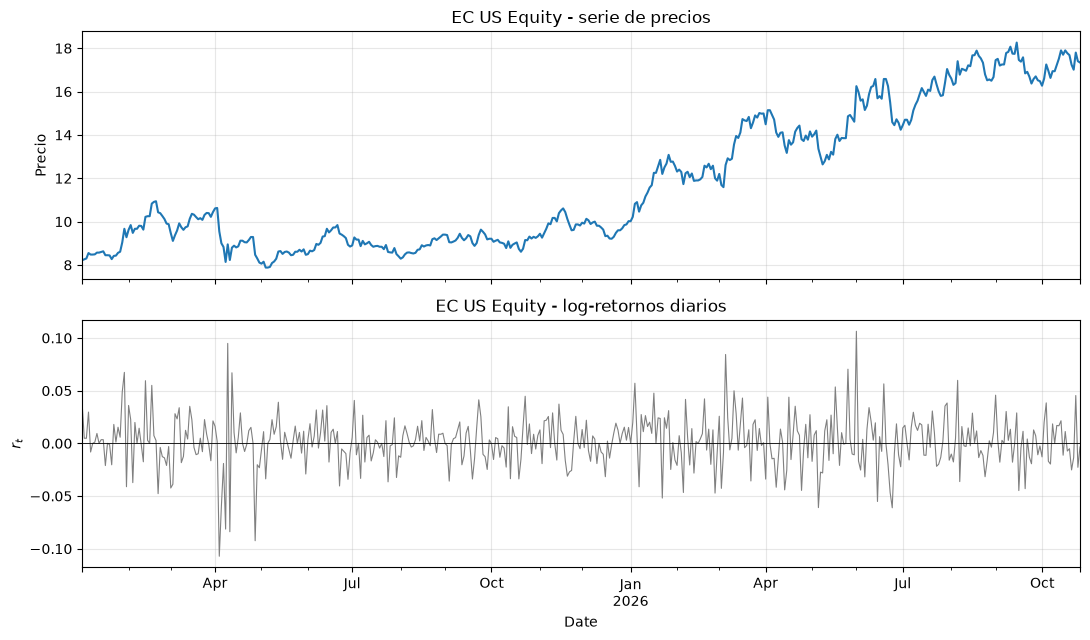

In [148]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
S.plot(ax=ax[0]); ax[0].set_title(f"{ASSET_NAME} - serie de precios"); ax[0].set_ylabel("Precio")
r.plot(ax=ax[1], color="gray", lw=.8); ax[1].axhline(0, color="k", lw=.6)
ax[1].set_title(f"{ASSET_NAME} - log-retornos diarios"); ax[1].set_ylabel("$r_t$")
plt.tight_layout(); plt.show()

## 5. Estimación de parámetros $\hat\mu$ y $\hat\sigma$

Siguiendo los apuntes del curso, a partir de la media $\bar r$ y la desviación
muestral $s_r$ de los log-retornos:
$$\hat\sigma=\frac{s_r}{\sqrt{\Delta t}},\qquad \hat\mu=\frac{\bar r}{\Delta t}+\frac{\hat\sigma^2}{2}.$$


In [149]:
r_bar, s_r = r.mean(), r.std(ddof=1)
sigma_hat = s_r / np.sqrt(dt)
mu_hat    = r_bar / dt + 0.5 * sigma_hat**2
se_mu     = s_r / np.sqrt(n) / dt

print(f"Activo: {ASSET_NAME}")
print(f"Media diaria log-ret  : {r_bar:.6f}")
print(f"Desv. diaria log-ret  : {s_r:.6f}")
print(f"σ̂ anualizada          : {sigma_hat:.2%}")
print(f"μ̂ anualizado          : {mu_hat:.2%}   (error estándar de r̄ anualizado ≈ {se_mu:.2%})")

Activo: EC US Equity
Media diaria log-ret  : 0.001653
Desv. diaria log-ret  : 0.024393
σ̂ anualizada          : 38.72%
μ̂ anualizado          : 49.16%   (error estándar de r̄ anualizado ≈ 28.23%)


## 6. C1 — Normalidad de los log-retornos

Asimetría = -0.066 | Curtosis en exceso = 2.578   (normal: 0 y 0)
Jarque-Bera        : stat=131.576  p=0.0000
Shapiro-Wilk       : stat=0.9683  p=0.0000
D'Agostino-Pearson : stat=33.576  p=0.0000


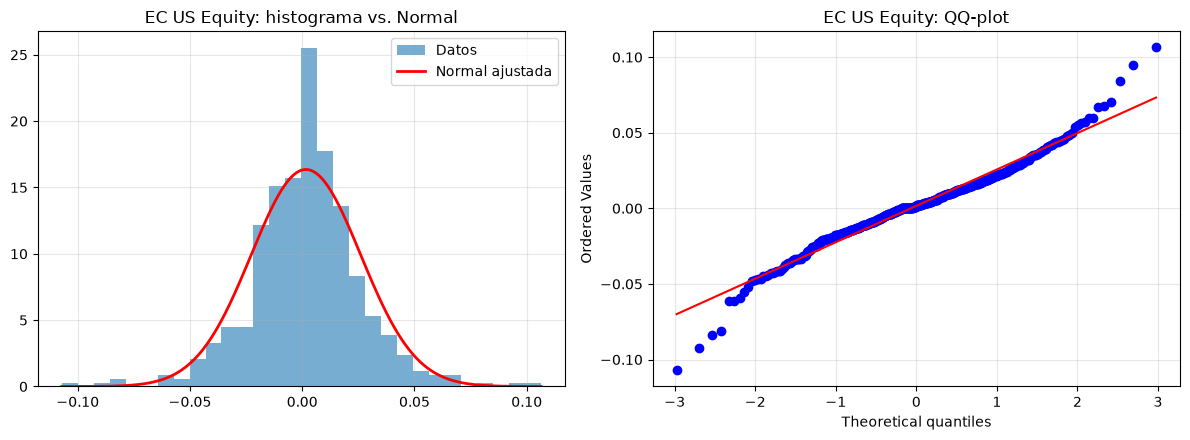


Observaciones más extremas (|z| > 3):


,log_ret,z
Date,,
2025-04-03,-0.1071,-4.4600
2025-04-08,-0.0814,-3.4034
2025-04-09,0.0949,3.8212
2025-04-10,-0.0839,-3.5059
2025-04-28,-0.0924,-3.8561
2026-03-05,0.0843,3.3901
2026-06-01,0.1064,4.2936


In [150]:
print(f"Asimetría = {stats.skew(r):.3f} | Curtosis en exceso = {stats.kurtosis(r):.3f}   (normal: 0 y 0)")
print(f"Jarque-Bera        : stat={stats.jarque_bera(r)[0]:.3f}  p={stats.jarque_bera(r)[1]:.4f}")
print(f"Shapiro-Wilk       : stat={stats.shapiro(r)[0]:.4f}  p={stats.shapiro(r)[1]:.4f}")
print(f"D'Agostino-Pearson : stat={stats.normaltest(r)[0]:.3f}  p={stats.normaltest(r)[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(r, bins=30, density=True, alpha=.6, label="Datos")
xg = np.linspace(r.min(), r.max(), 400)
ax[0].plot(xg, stats.norm.pdf(xg, r_bar, s_r), "r", lw=2, label="Normal ajustada")
ax[0].set_title(f"{ASSET_NAME}: histograma vs. Normal"); ax[0].legend()
stats.probplot(r, dist="norm", plot=ax[1]); ax[1].set_title(f"{ASSET_NAME}: QQ-plot")
plt.tight_layout(); plt.show()

z = (r - r_bar) / s_r
print("\nObservaciones más extremas (|z| > 3):")
display(pd.DataFrame({"log_ret": r[z.abs() > 3], "z": z[z.abs() > 3]}).round(4))

## 7. C2 — Independencia | C3 — Varianza constante

Ljung-Box r   (lags= 5) p = 0.4632
Ljung-Box r   (lags=10) p = 0.4589
Ljung-Box r   (lags=20) p = 0.4341
Test de rachas           p = 0.7130
Ljung-Box r²  (lags= 5) p = 0.0000
Ljung-Box r²  (lags=10) p = 0.0000
Ljung-Box r²  (lags=20) p = 0.0000
ARCH-LM (q=5)            p = 0.0000


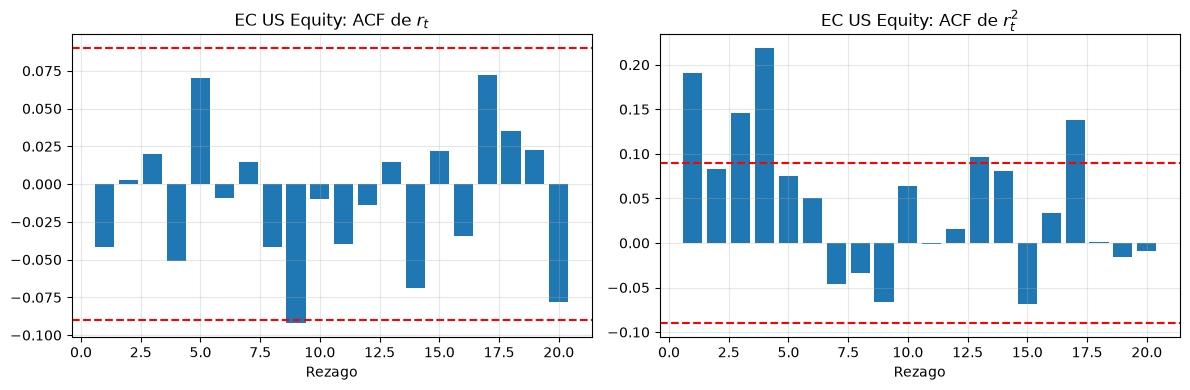

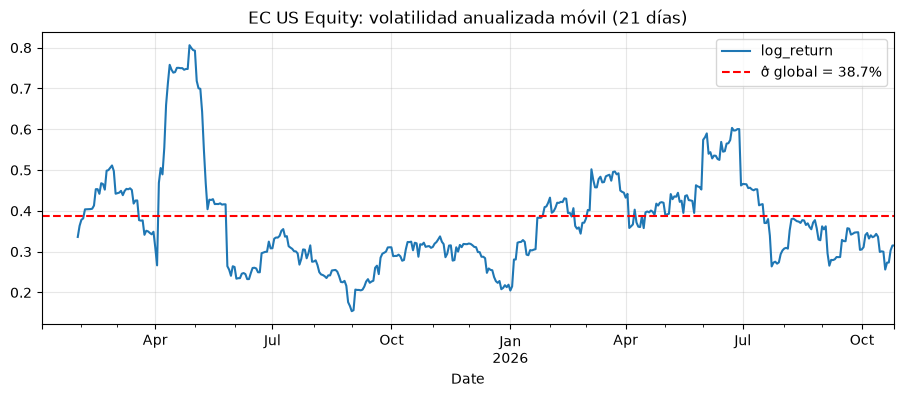

In [151]:
conf = 1.96 / np.sqrt(n)
for h in (5, 10, 20):
    print(f"Ljung-Box r   (lags={h:2d}) p = {ljung_box(r, h)[1]:.4f}")
print(f"Test de rachas           p = {runs_test(r)[1]:.4f}")
for h in (5, 10, 20):
    print(f"Ljung-Box r²  (lags={h:2d}) p = {ljung_box(r**2, h)[1]:.4f}")
print(f"ARCH-LM (q=5)            p = {arch_lm(r, 5)[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, y, t in zip(ax, (r, r**2), ("ACF de $r_t$", "ACF de $r_t^2$")):
    a.bar(range(1, 21), acf(y, 20)); a.set_title(f"{ASSET_NAME}: {t}"); a.set_xlabel("Rezago")
    a.axhline(conf, color="r", ls="--"); a.axhline(-conf, color="r", ls="--")
plt.tight_layout(); plt.show()

w = 21   # ≈ un mes
ax = (r.rolling(w).std() / np.sqrt(dt)).plot(figsize=(11, 3.8),
        title=f"{ASSET_NAME}: volatilidad anualizada móvil ({w} días)")
ax.axhline(sigma_hat, color="r", ls="--", label=f"σ̂ global = {sigma_hat:.1%}"); ax.legend(); plt.show()

## 8. C4 — Estabilidad de parámetros entre subperiodos

In [152]:
h = n // 2; r1, r2 = r.iloc[:h], r.iloc[h:]
print(f"Mitad 1 ({r1.index[0].date()} → {r1.index[-1].date()}): media anual={r1.mean()/dt:.3f}  vol anual={r1.std()/np.sqrt(dt):.3f}")
print(f"Mitad 2 ({r2.index[0].date()} → {r2.index[-1].date()}): media anual={r2.mean()/dt:.3f}  vol anual={r2.std()/np.sqrt(dt):.3f}")
print(f"t-test medias  p = {stats.ttest_ind(r1, r2, equal_var=False)[1]:.4f}")
print(f"Levene         p = {stats.levene(r1, r2)[1]:.4f}")
print(f"KS 2 muestras  p = {stats.ks_2samp(r1, r2)[1]:.4f}")

Mitad 1 (2025-01-02 → 2025-11-28): media anual=0.229  vol anual=0.383
Mitad 2 (2025-12-01 → 2026-10-27): media anual=0.605  vol anual=0.391
t-test medias  p = 0.5061
Levene         p = 0.1881
KS 2 muestras  p = 0.2593


## 9. C5 — Simulación Monte Carlo vs. trayectoria real

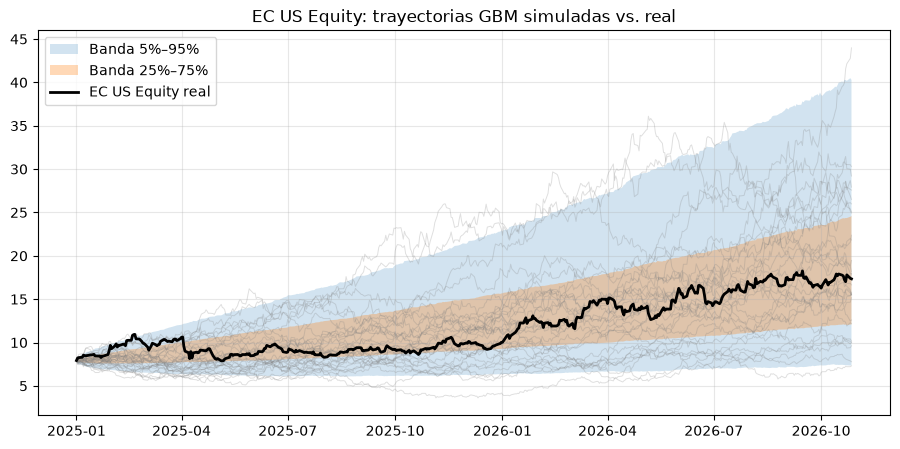

Percentil del precio final real en la simulación : 51.1%
% de días con precio real dentro de banda 5–95% : 99.4%


In [153]:
Z = np.random.standard_normal((N_PATHS_C5, n))
inc = (mu_hat - 0.5 * sigma_hat**2) * dt + sigma_hat * np.sqrt(dt) * Z
paths_c5 = S.iloc[0] * np.exp(np.hstack([np.zeros((N_PATHS_C5, 1)), np.cumsum(inc, axis=1)]))
q = np.percentile(paths_c5, [5, 25, 50, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(S.index, paths_c5[:30].T, color="gray", alpha=.25, lw=.7)
ax.fill_between(S.index, q[0], q[4], alpha=.2, label="Banda 5%–95%")
ax.fill_between(S.index, q[1], q[3], alpha=.3, label="Banda 25%–75%")
ax.plot(S.index, S.values, "k", lw=2, label=f"{ASSET_NAME} real"); ax.legend()
ax.set_title(f"{ASSET_NAME}: trayectorias GBM simuladas vs. real"); plt.show()

print(f"Percentil del precio final real en la simulación : {(paths_c5[:, -1] < S.iloc[-1]).mean():.1%}")
print(f"% de días con precio real dentro de banda 5–95% : {np.mean((S.values >= q[0]) & (S.values <= q[4])):.1%}")

## 10. Robustez: ¿el resultado depende del subperiodo?

In [154]:
rows = []
for label, sub in [("Todo el periodo", r),
                   ("Primera mitad", r.iloc[:n // 2]),
                   ("Segunda mitad", r.iloc[n // 2:])]:
    if len(sub) >= 50:
        p = battery(sub)
        rows.append({"Ventana": label, "N": len(sub),
                     **{k: round(v, 4) for k, v in p.items()},
                     "Rechazos 5%": sum(v < ALPHA for v in p.values()),
                     "Rechazos Bonf.": sum(v < ALPHA / 9 for v in p.values())})
robust = pd.DataFrame(rows).set_index("Ventana")
display(robust.T)

Ventana,Todo el periodo,Primera mitad,Segunda mitad
N,474.0000,237.0000,237.0000
C1 Jarque-Bera,0.0000,0.0000,0.0000
C1 Shapiro-Wilk,0.0000,0.0000,0.0024
C2 Ljung-Box r (10),0.4589,0.0963,0.8053
C2 Test de rachas,0.7130,0.3290,0.2683
C3 Ljung-Box r2 (10),0.0000,0.0000,0.0024
C3 ARCH-LM (5),0.0000,0.0000,0.0240
C4 t-test medias,0.5061,0.6889,0.9471
C4 Levene varianzas,0.1881,0.0167,0.8005
C4 KS 2 muestras,0.2593,0.6795,0.6992


## 11. Tabla final de pruebas y conclusión sobre el MBG

In [155]:
pv = battery(r)
final = pd.DataFrame({"Prueba": list(pv), "p-valor": [round(v, 4) for v in pv.values()]})
final["Resultado (α=5%)"]       = np.where(final["p-valor"] < ALPHA, "❌ Se rechaza H0", "✅ No se rechaza H0")
final["Resultado (Bonferroni)"] = np.where(final["p-valor"] < ALPHA / len(final), "❌ Se rechaza H0", "✅ No se rechaza H0")
display(final)

rej   = int((final["p-valor"] < ALPHA).sum())
rej_b = int((final["p-valor"] < ALPHA / len(final)).sum())
print("=" * 72)
print(f"Activo: {ASSET_NAME}  |  {n} log-retornos")
print(f"Rechazos con α=5%: {rej}/9   |   con α corregido ({ALPHA/len(final):.4f}): {rej_b}/9")
if rej == 0:
    print(f"CONCLUSIÓN: ninguna prueba rechaza los supuestos del GBM. {ASSET_NAME} es COMPATIBLE\n"
          f"con un GBM (σ̂={sigma_hat:.1%}, μ̂={mu_hat:.1%}).")
elif rej_b == 0:
    print(f"CONCLUSIÓN: {rej} prueba(s) rechazan al 5% pero ninguna con el umbral corregido.\n"
          f"{ASSET_NAME} es COMPATIBLE con un GBM bajo el criterio de Bonferroni (σ̂={sigma_hat:.1%}, μ̂={mu_hat:.1%}).")
else:
    failed = ", ".join(final.loc[final["p-valor"] < ALPHA / len(final), "Prueba"])
    print(f"CONCLUSIÓN: se rechazan supuestos incluso con el umbral corregido ({failed}).\n"
          f"No puede afirmarse que {ASSET_NAME} siga un GBM; el modelo es solo una aproximación.")

,Prueba,p-valor,Resultado (α=5%),Resultado (Bonferroni)
0,C1 Jarque-Bera,0.0000,❌ Se rechaza H0,❌ Se rechaza H0
1,C1 Shapiro-Wilk,0.0000,❌ Se rechaza H0,❌ Se rechaza H0
2,C2 Ljung-Box r (10),0.4589,✅ No se rechaza H0,✅ No se rechaza H0
3,C2 Test de rachas,0.7130,✅ No se rechaza H0,✅ No se rechaza H0
4,C3 Ljung-Box r2 (10),0.0000,❌ Se rechaza H0,❌ Se rechaza H0
5,C3 ARCH-LM (5),0.0000,❌ Se rechaza H0,❌ Se rechaza H0
6,C4 t-test medias,0.5061,✅ No se rechaza H0,✅ No se rechaza H0
7,C4 Levene varianzas,0.1881,✅ No se rechaza H0,✅ No se rechaza H0
8,C4 KS 2 muestras,0.2593,✅ No se rechaza H0,✅ No se rechaza H0


Activo: EC US Equity  |  474 log-retornos
Rechazos con α=5%: 4/9   |   con α corregido (0.0056): 4/9
CONCLUSIÓN: se rechazan supuestos incluso con el umbral corregido (C1 Jarque-Bera, C1 Shapiro-Wilk, C3 Ljung-Box r2 (10), C3 ARCH-LM (5)).
No puede afirmarse que EC US Equity siga un GBM; el modelo es solo una aproximación.


## 12. Pronóstico dentro de muestra (in-sample) — 10.000 simulaciones

Con $(\hat\mu,\hat\sigma)$ se simulan **10.000 trayectorias GBM** sobre el mismo
periodo observado y se compara el pronóstico con la serie real:

- **(a) Multi-paso:** las trayectorias parten del primer precio y se comparan con toda la serie (los errores se acumulan).
- **(b) Un paso adelante:** en cada fecha $t$ se simula $S_t$ a partir del precio real $S_{t-1}$.

Se reportan métricas de ajuste y precisión. **El enunciado espera MAPE < 5 %**
(se evalúa sobre el pronóstico un-paso-adelante, el pronóstico inducido sobre la muestra).


In [156]:
rng = np.random.default_rng(SEED)

S_obs = S.values.astype(float)
drift_log = (mu_hat - 0.5 * sigma_hat**2) * dt      # media del log-retorno por periodo (= r̄)
vol_step  = sigma_hat * np.sqrt(dt)                 # desv. del log-retorno por periodo (= s_r)

# (a) Multi-paso desde el primer precio
Z_in = rng.standard_normal((N_SIM, n))
sim_ret = drift_log + vol_step * Z_in
sim_a = S_obs[0] * np.exp(np.hstack([np.zeros((N_SIM, 1)), np.cumsum(sim_ret, axis=1)]))   # (N_SIM, len(S))

# (b) Un paso adelante
Z_1 = rng.standard_normal((N_SIM, n))
sim_b = S_obs[:-1] * np.exp(drift_log + vol_step * Z_1)                                     # (N_SIM, n)

y_a, f_a = S_obs[1:], sim_a[:, 1:].mean(axis=0)
y_b, f_b = S_obs[1:], sim_b.mean(axis=0)

pm_a = point_metrics(y_a, f_a, y_naive=np.full_like(y_a, S_obs[0]))   # ingenuo: S0 constante
pm_b = point_metrics(y_b, f_b, y_naive=S_obs[:-1])                    # ingenuo: paseo aleatorio S_{t-1}
pb_a, pit_a = prob_metrics(y_a, sim_a[:, 1:])
pb_b, pit_b = prob_metrics(y_b, sim_b)

met = pd.DataFrame({"(a) Multi-paso desde S₀": {**pm_a, **pb_a},
                    "(b) Un paso adelante":   {**pm_b, **pb_b}})
display(met.round(4))

mape_is = met.loc["MAPE (%)", "(b) Un paso adelante"]
print(f"\nMAPE in-sample (un paso adelante) para {ASSET_NAME}: {mape_is:.3f}% "
      f"-> {'✅ CUMPLE' if mape_is < 5 else '❌ NO cumple'} el criterio del enunciado (< 5%).")

,(a) Multi-paso desde S₀,(b) Un paso adelante
Sesgo ME (obs - pron.),-1.3142,-0.0030
MAE,1.6187,0.2102
RMSE,1.8416,0.2977
MAPE (%),14.8385,1.7602
sMAPE (%),13.6841,1.7586
R2,0.6580,0.9911
Correlacion,0.9284,0.9955
Theil U (vs. ingenuo),0.3706,0.9987
Cobertura IC 50 % (nominal 50 %),0.8713,0.5992
Cobertura IC 95 % (nominal 95 %),1.0000,0.9473



MAPE in-sample (un paso adelante) para EC US Equity: 1.760% -> ✅ CUMPLE el criterio del enunciado (< 5%).


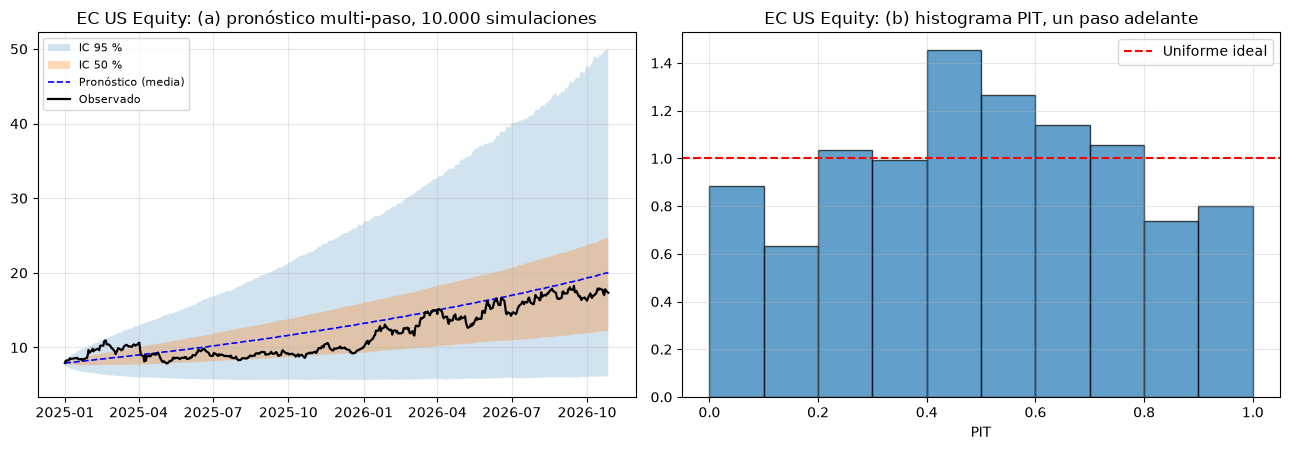

In [157]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
idx = S.index
lo, q25, med, q75, hi = np.percentile(sim_a, [2.5, 25, 50, 75, 97.5], axis=0)
ax[0].fill_between(idx, lo, hi, alpha=.2, label="IC 95 %")
ax[0].fill_between(idx, q25, q75, alpha=.3, label="IC 50 %")
ax[0].plot(idx, sim_a.mean(axis=0), "b--", lw=1.2, label="Pronóstico (media)")
ax[0].plot(idx, S_obs, "k", lw=1.6, label="Observado")
ax[0].set_title(f"{ASSET_NAME}: (a) pronóstico multi-paso, 10.000 simulaciones"); ax[0].legend(fontsize=8)

ax[1].hist(pit_b, bins=10, range=(0, 1), density=True, alpha=.7, edgecolor="k")
ax[1].axhline(1, color="r", ls="--", label="Uniforme ideal")
ax[1].set_title(f"{ASSET_NAME}: (b) histograma PIT, un paso adelante"); ax[1].set_xlabel("PIT"); ax[1].legend()
plt.tight_layout(); plt.show()

### Bondad de ajuste de la distribución de retornos

Se compara cada estadístico de los log-retornos **observados** con su distribución en las 10.000 trayectorias simuladas. Un *p-valor MC* < 0,05 indicaría desajuste del modelo.

In [158]:
fns = {
    "media":              lambda x: x.mean(axis=-1),
    "desv. estándar":     lambda x: x.std(axis=-1, ddof=1),
    "asimetría":          lambda x: stats.skew(x, axis=-1),
    "curtosis en exceso": lambda x: stats.kurtosis(x, axis=-1),
    "mínimo":             lambda x: x.min(axis=-1),
    "máximo":             lambda x: x.max(axis=-1),
    "retorno acumulado":  lambda x: x.sum(axis=-1),
}
rows = []
for name, f in fns.items():
    obs_v, sim_v = f(r.values), f(sim_ret)
    p_mc = min(1.0, 2 * min((sim_v <= obs_v).mean(), (sim_v >= obs_v).mean()))
    rows.append({"Estadístico": name, "Observado": obs_v, "Sim. media": sim_v.mean(),
                 "Sim. 2,5 %": np.percentile(sim_v, 2.5), "Sim. 97,5 %": np.percentile(sim_v, 97.5),
                 "p-valor MC": p_mc})
gof = pd.DataFrame(rows).set_index("Estadístico")
display(gof.round(5))

ks = stats.ks_2samp(r.values, sim_ret.ravel())
print(f"KS 2 muestras (retornos observados vs. simulados): D = {ks.statistic:.4f}, p = {ks.pvalue:.4f}")
bad = gof.index[gof['p-valor MC'] < ALPHA].tolist()
print("Estadísticos con p-valor MC < 5%:", bad if bad else "ninguno (el modelo reproduce los momentos observados).")

,Observado,Sim. media,"Sim. 2,5 %","Sim. 97,5 %",p-valor MC
Estadístico,,,,,
media,0.00165,0.00166,-0.00054,0.00389,0.9996
desv. estándar,0.02439,0.02438,0.02282,0.02593,0.9914
asimetría,-0.06578,0.00151,-0.20953,0.22229,0.5384
curtosis en exceso,2.57775,-0.01174,-0.38984,0.48842,0.0000
mínimo,-0.10714,-0.07196,-0.09349,-0.05740,0.0040
máximo,0.10639,0.07534,0.06089,0.09609,0.0080
retorno acumulado,0.78362,0.78680,-0.25675,1.84269,0.9996


KS 2 muestras (retornos observados vs. simulados): D = 0.0555, p = 0.1042
Estadísticos con p-valor MC < 5%: ['curtosis en exceso', 'mínimo', 'máximo']


## 13. Pronóstico fuera de muestra (out-of-sample) y generación de strikes

Para cada $T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$ se simulan **10.000 trayectorias**
desde el último precio observado $S_0$ con el GBM estimado $(\hat\mu,\hat\sigma)$.
Los **5 strikes** son los **percentiles 10, 25, 50, 75 y 90 de $S_T$** simulado,
**redondeados a 2 decimales**.


In [159]:
S0_last = float(round(S_obs[-1], PRICE_DECIMALS))
sig = sigma_hat

rng_oos = np.random.default_rng(7)
oos, strikes = {}, {}
for T in T_LIST:
    steps = int(round(T * PPY))
    Zo = rng_oos.standard_normal((N_SIM, steps))
    paths = S0_last * np.exp(np.cumsum(drift_log + vol_step * Zo, axis=1))
    oos[T] = paths
    strikes[T] = np.round(np.percentile(paths[:, -1], PCTS), PRICE_DECIMALS)   # strikes a 2 decimales

print(f"Activo: {ASSET_NAME}")
print(f"S0 (último precio observado, {S.index[-1].date()}) = {S0_last:.2f} | "
      f"σ̂ = {sig:.4%} | r = {r_free:.2%} | q = {q_yield:.2%}\n")
display(pd.DataFrame({f"T={T:.4g}": strikes[T] for T in T_LIST}, index=[f"P{p}" for p in PCTS]).T)

Activo: EC US Equity
S0 (último precio observado, 2026-10-27) = 17.34 | σ̂ = 38.7227% | r = 5.00% | q = 0.00%



,P10,P25,P50,P75,P90
T=1,16.1441,20.2123,26.3796,34.0740,43.2338
T=0.5,15.0499,17.7878,21.3856,25.6518,29.9881
T=0.3333,14.9588,17.2210,19.9787,23.1124,26.5638
T=0.25,14.9768,16.8755,19.2415,21.9511,24.6656


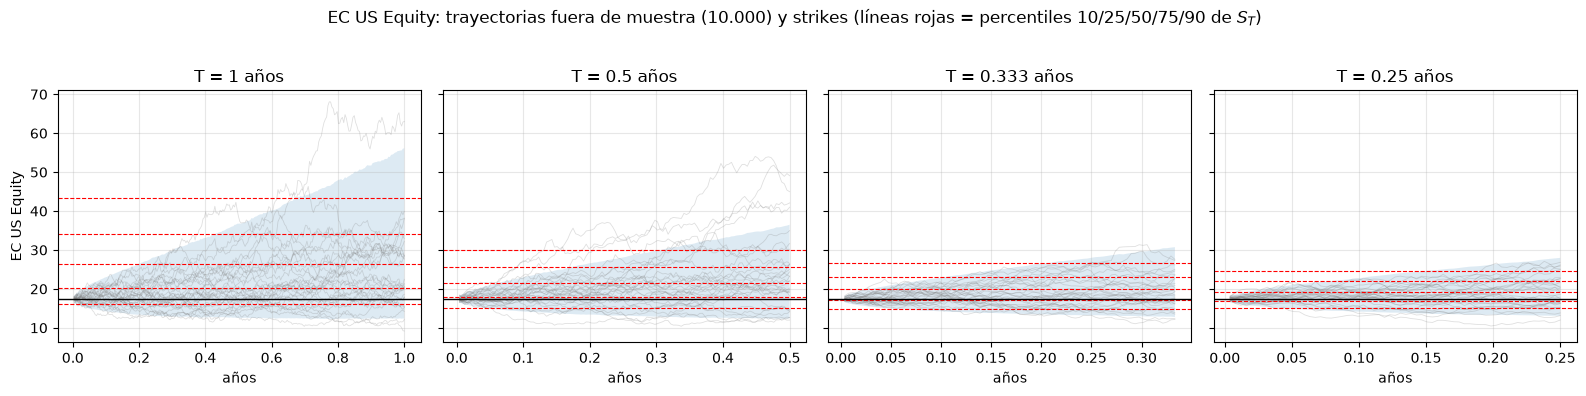

In [160]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, T in zip(axs, T_LIST):
    P = oos[T]; tt = np.arange(1, P.shape[1] + 1) / PPY
    ax.plot(tt, P[:30].T, color="gray", alpha=.25, lw=.6)
    ax.fill_between(tt, *np.percentile(P, [2.5, 97.5], axis=0), alpha=.15)
    for K in strikes[T]:
        ax.axhline(K, color="r", lw=.8, ls="--")
    ax.axhline(S0_last, color="k", lw=1); ax.set_title(f"T = {T:.3g} años"); ax.set_xlabel("años")
axs[0].set_ylabel(ASSET_NAME)
plt.suptitle(f"{ASSET_NAME}: trayectorias fuera de muestra (10.000) y strikes "
             f"(líneas rojas = percentiles 10/25/50/75/90 de $S_T$)", y=1.03)
plt.tight_layout(); plt.show()

## 14. Valoración de opciones europeas: 4 métodos

Se valoran opciones **Call europeas** (prioridad del enunciado) y Puts como
control, con los cuatro métodos bajo medida neutral al riesgo (deriva $r-q$,
volatilidad $\hat\sigma$):

1. **Black-Scholes** (fórmula cerrada) — referencia.
2. **Monte Carlo** con solución exacta del MBG y variables antitéticas (+ error estándar).
3. **Árbol binomial CRR** con $N$ pasos.
4. **Diferencias finitas explícitas** sobre la EDP de BS en $x=\ln S$.

Parámetros del enunciado: $r=0.05$, $S_0=$ último precio, $\sigma=\hat\sigma$,
$T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$ y los 5 strikes por $T$.


In [161]:
rng_mc = np.random.default_rng(123)
rows, timing = [], {"Black-Scholes": 0.0, "Monte Carlo": 0.0, "Árbol binomial": 0.0, "Dif. finitas": 0.0}
fd_steps = {}
for T in T_LIST:
    Zh = rng_mc.standard_normal(N_SIM // 2)                 # mismas Z para todos los strikes de un T
    for pct, K in zip(PCTS, strikes[T]):
        for kind in OPTION_KINDS:
            t0 = time.perf_counter(); bs = bs_price(S0_last, K, T, r_free, q_yield, sig, kind);          timing["Black-Scholes"] += time.perf_counter() - t0
            t0 = time.perf_counter(); mc, se = mc_price(S0_last, K, T, r_free, q_yield, sig, Zh, kind);   timing["Monte Carlo"]   += time.perf_counter() - t0
            t0 = time.perf_counter(); bi = binomial_crr(S0_last, K, T, r_free, q_yield, sig, kind, N=N_BIN); timing["Árbol binomial"] += time.perf_counter() - t0
            t0 = time.perf_counter(); fd, nt = fd_explicit(S0_last, K, T, r_free, q_yield, sig, kind, Nh=NH_FD); timing["Dif. finitas"] += time.perf_counter() - t0
            fd_steps[round(T, 3)] = nt
            rel = lambda x: abs(x - bs) / bs if bs > 1e-12 else np.nan
            rows.append({"T": round(T, 4), "Pctl": f"P{pct}", "K": K, "Tipo": kind,
                         "BS": bs, "MC": mc, "EE MC": se, "Binomial": bi, "DF explícitas": fd,
                         "ErrRel MC": rel(mc), "ErrRel Bin": rel(bi), "ErrRel DF": rel(fd),
                         "|MC−BS|": abs(mc - bs), "|Bin−BS|": abs(bi - bs), "|DF−BS|": abs(fd - bs)})
opt = pd.DataFrame(rows)
print(f"Pasos de tiempo en diferencias finitas por T (estabilidad): {fd_steps}")
display(opt.round(6))

Pasos de tiempo en diferencias finitas por T (estabilidad): {1: 2720, 0.5: 2737, 0.333: 2744, 0.25: 2749}


,T,Pctl,K,Tipo,BS,MC,EE MC,Binomial,DF explícitas,ErrRel MC,ErrRel Bin,ErrRel DF,|MC−BS|,|Bin−BS|,|DF−BS|
0,1.0000,P10,16.1441,call,3.622216,3.630773,0.041580,3.621969,3.622280,0.002362,0.000068,0.000018,0.008557,0.000246,0.000064
1,1.0000,P10,16.1441,put,1.638959,1.646016,0.017720,1.638712,1.639013,0.004306,0.000150,0.000033,0.007057,0.000246,0.000055
2,1.0000,P25,20.2123,call,1.961508,1.970525,0.038393,1.961785,1.961629,0.004597,0.000141,0.000062,0.009017,0.000277,0.000121
3,1.0000,P25,20.2123,put,3.848043,3.855560,0.013857,3.848319,3.848153,0.001953,0.000072,0.000029,0.007517,0.000277,0.000110
4,1.0000,P50,26.3796,call,0.724911,0.723370,0.025987,0.724605,0.724930,0.002126,0.000422,0.000026,0.001541,0.000306,0.000019
5,1.0000,P50,26.3796,put,8.477963,8.474922,0.007359,8.477657,8.477968,0.000359,0.000036,0.000001,0.003041,0.000306,0.000005
6,1.0000,P75,34.0740,call,0.202914,0.190811,0.013604,0.202856,0.202859,0.059646,0.000286,0.000271,0.012103,0.000058,0.000055
7,1.0000,P75,34.0740,put,15.275106,15.261503,0.016776,15.275048,15.275034,0.000891,0.000004,0.000005,0.013603,0.000058,0.000072
8,1.0000,P90,43.2338,call,0.045655,0.034666,0.005466,0.045535,0.045609,0.240698,0.002628,0.000992,0.010989,0.000120,0.000045
9,1.0000,P90,43.2338,put,23.830917,23.818429,0.022807,23.830797,23.830851,0.000524,0.000005,0.000003,0.012489,0.000120,0.000066


### 14.1 Tabla de precios y error relativo de las Calls europeas (prioridad del enunciado)

In [162]:
calls = opt[opt["Tipo"] == "call"].copy()
tabla_calls = calls[["T", "Pctl", "K", "BS", "MC", "Binomial", "DF explícitas",
                     "ErrRel MC", "ErrRel Bin", "ErrRel DF"]].copy()
# Precios a 2 decimales; errores relativos en %
for c in ["BS", "MC", "Binomial", "DF explícitas"]:
    tabla_calls[c] = tabla_calls[c].round(PRICE_DECIMALS)
for c in ["ErrRel MC", "ErrRel Bin", "ErrRel DF"]:
    tabla_calls[c] = (100 * tabla_calls[c]).round(4)
tabla_calls = tabla_calls.rename(columns={"ErrRel MC": "ErrRel MC (%)",
                                          "ErrRel Bin": "ErrRel Bin (%)",
                                          "ErrRel DF": "ErrRel DF (%)"})
print(f"Opciones CALL europeas sobre {ASSET_NAME}  (S0={S0_last:.2f}, r={r_free:.0%}, σ̂={sig:.2%})")
display(tabla_calls.reset_index(drop=True))

Opciones CALL europeas sobre EC US Equity  (S0=17.34, r=5%, σ̂=38.72%)


,T,Pctl,K,BS,MC,Binomial,DF explícitas,ErrRel MC (%),ErrRel Bin (%),ErrRel DF (%)
0,1.0000,P10,16.1441,3.6222,3.6308,3.6220,3.6223,0.2362,0.0068,0.0018
1,1.0000,P25,20.2123,1.9615,1.9705,1.9618,1.9616,0.4597,0.0141,0.0062
2,1.0000,P50,26.3796,0.7249,0.7234,0.7246,0.7249,0.2126,0.0422,0.0026
3,1.0000,P75,34.0740,0.2029,0.1908,0.2029,0.2029,5.9646,0.0286,0.0271
4,1.0000,P90,43.2338,0.0457,0.0347,0.0455,0.0456,24.0698,0.2628,0.0992
5,0.5000,P10,15.0499,3.3846,3.3646,3.3846,3.3846,0.5884,0.0010,0.0017
6,0.5000,P25,17.7878,1.8844,1.8651,1.8849,1.8845,1.0259,0.0242,0.0046
7,0.5000,P50,21.3856,0.7725,0.7551,0.7723,0.7725,2.2624,0.0258,0.0045
8,0.5000,P75,25.6518,0.2374,0.2278,0.2374,0.2373,4.0238,0.0122,0.0239
9,0.5000,P90,29.9881,0.0661,0.0642,0.0660,0.0660,2.7531,0.0881,0.0518


## 15. Resumen de precisión frente a Black-Scholes

In [163]:
summ = pd.DataFrame({
    "Monte Carlo":    opt["|MC−BS|"],
    "Árbol binomial": opt["|Bin−BS|"],
    "Dif. finitas":   opt["|DF−BS|"],
}).agg(["mean", "max"]).T
summ.columns = ["Error abs. medio", "Error abs. máximo"]
summ["RMSE"] = [np.sqrt(((opt["MC"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["Binomial"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["DF explícitas"] - opt["BS"])**2).mean())]
summ["Tiempo total (s)"] = [timing["Monte Carlo"], timing["Árbol binomial"], timing["Dif. finitas"]]
display(summ.applymap(lambda v: f"{v:.3e}") if hasattr(summ, "applymap") else summ)

inside = (np.abs(opt["MC"] - opt["BS"]) <= 1.96 * opt["EE MC"]).mean()
print(f"\nMonte Carlo: BS cae dentro de ±1,96·EE en {inside:.1%} de los casos (esperado ≈ 95 %).")
print(f"Tiempo de Black-Scholes (referencia): {timing['Black-Scholes']:.4f} s")

# Paridad put-call (control de consistencia): C − P = S0·e^{-qT} − K·e^{-rT}
if set(OPTION_KINDS) >= {"call", "put"}:
    par = []
    for (T, K), g in opt.groupby(["T", "K"]):
        c, p = g[g.Tipo == "call"].iloc[0], g[g.Tipo == "put"].iloc[0]
        th = S0_last * np.exp(-q_yield * T) - K * np.exp(-r_free * T)
        par.append({"BS": (c.BS - p.BS) - th, "MC": (c.MC - p.MC) - th,
                    "Binomial": (c.Binomial - p.Binomial) - th,
                    "DF": (c["DF explícitas"] - p["DF explícitas"]) - th})
    par = pd.DataFrame(par).abs().max()
    print("\nMáx. desviación de la paridad put-call (|C − P − teórico|):")
    display(par.map(lambda v: f"{v:.2e}").to_frame("desviación"))

,Error abs. medio,Error abs. máximo,RMSE,Tiempo total (s)
Monte Carlo,0.007515,0.019916,0.008961,0.009012
Árbol binomial,0.000177,0.000456,0.000220,0.188819
Dif. finitas,0.000043,0.000121,0.000051,0.862867



Monte Carlo: BS cae dentro de ±1,96·EE en 95.0% de los casos (esperado ≈ 95 %).
Tiempo de Black-Scholes (referencia): 0.0129 s

Máx. desviación de la paridad put-call (|C − P − teórico|):


,desviación
BS,4.35e-05
MC,1.06e-02
Binomial,4.35e-05
DF,4.51e-05


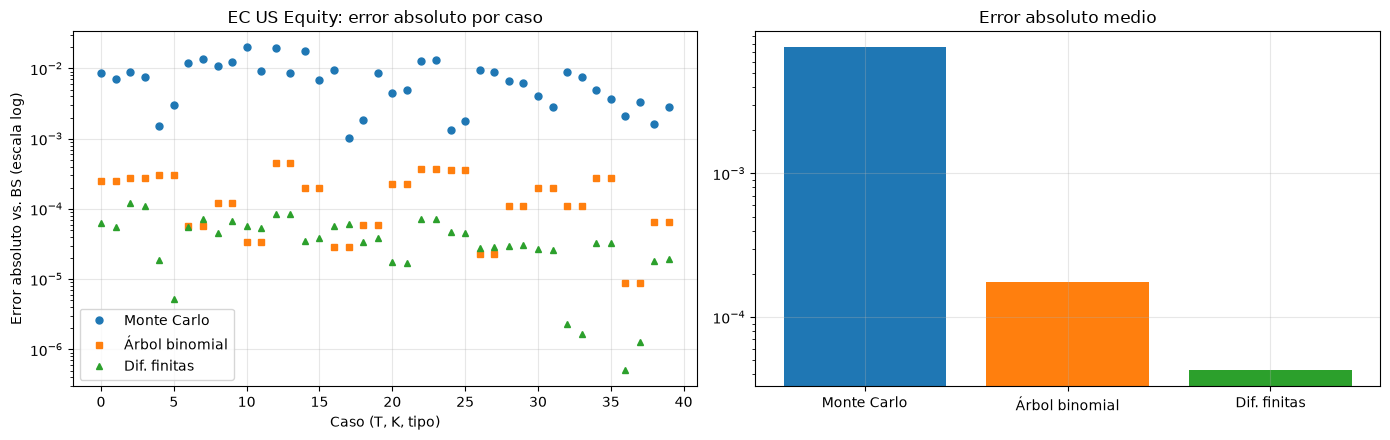

In [164]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(opt))
for col, lab, mk in [("|MC−BS|", "Monte Carlo", "o"), ("|Bin−BS|", "Árbol binomial", "s"), ("|DF−BS|", "Dif. finitas", "^")]:
    ax[0].semilogy(x, opt[col].clip(lower=1e-12), mk, label=lab, ms=5)
ax[0].set_xlabel("Caso (T, K, tipo)"); ax[0].set_ylabel("Error absoluto vs. BS (escala log)")
ax[0].set_title(f"{ASSET_NAME}: error absoluto por caso"); ax[0].legend()
ax[1].bar(["Monte Carlo", "Árbol binomial", "Dif. finitas"],
          [opt["|MC−BS|"].mean(), opt["|Bin−BS|"].mean(), opt["|DF−BS|"].mean()],
          color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set_yscale("log"); ax[1].set_title("Error absoluto medio")
plt.tight_layout(); plt.show()

### Convergencia (Call ATM, T = 1)

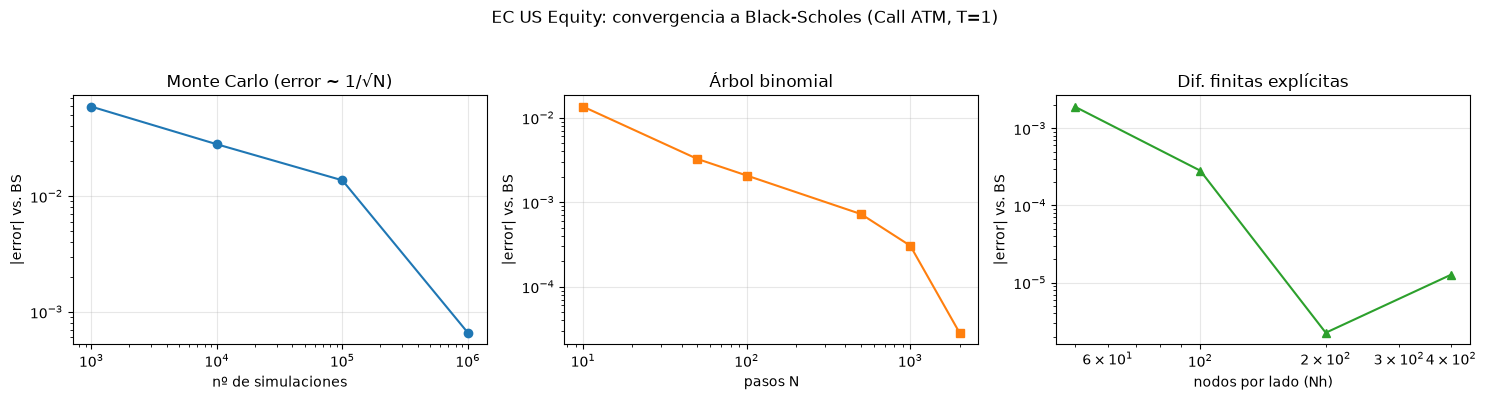

Precio BS de referencia (ATM, T=1, K=26.38) para EC US Equity: 0.7249


In [165]:
K_atm, T_c = float(strikes[1][2]), 1.0
bs_ref = bs_price(S0_last, K_atm, T_c, r_free, q_yield, sig, "call")
rng_c = np.random.default_rng(99)
Ns_mc  = [10**k for k in (3, 4, 5, 6)]
Ns_bin = [10, 50, 100, 500, 1000, 2000]
Nh_fd  = [50, 100, 200, 400]

err_mc  = [abs(mc_price(S0_last, K_atm, T_c, r_free, q_yield, sig, rng_c.standard_normal(N // 2), "call")[0] - bs_ref) for N in Ns_mc]
err_bin = [abs(binomial_crr(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", N=N) - bs_ref) for N in Ns_bin]
err_fd  = [abs(fd_explicit(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", Nh=h)[0] - bs_ref) for h in Nh_fd]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].loglog(Ns_mc, err_mc, "o-"); ax[0].set_title("Monte Carlo (error ~ 1/√N)"); ax[0].set_xlabel("nº de simulaciones")
ax[1].loglog(Ns_bin, err_bin, "s-", color="tab:orange"); ax[1].set_title("Árbol binomial"); ax[1].set_xlabel("pasos N")
ax[2].loglog(Nh_fd, err_fd, "^-", color="tab:green"); ax[2].set_title("Dif. finitas explícitas"); ax[2].set_xlabel("nodos por lado (Nh)")
for a in ax: a.set_ylabel("|error| vs. BS")
plt.suptitle(f"{ASSET_NAME}: convergencia a Black-Scholes (Call ATM, T=1)", y=1.04)
plt.tight_layout(); plt.show()
print(f"Precio BS de referencia (ATM, T=1, K={K_atm:.2f}) para {ASSET_NAME}: {bs_ref:.4f}")

## 16. Conclusiones cuantitativas

In [166]:
best = summ["Error abs. medio"].idxmin()
print(f"Activo: {ASSET_NAME}")
print(f"Método numérico más cercano a Black-Scholes (menor error absoluto medio): {best}.")
print("• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.")
print("• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.")
print("• Al aumentar K, el precio de la Call disminuye (menor probabilidad de terminar ITM); al aumentar T, la Call se encarece (más valor temporal).")
print("• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.")

Activo: EC US Equity
Método numérico más cercano a Black-Scholes (menor error absoluto medio): Dif. finitas.
• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.
• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.
• Al aumentar K, el precio de la Call disminuye (menor probabilidad de terminar ITM); al aumentar T, la Call se encarece (más valor temporal).
• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.


## 17. Notas finales y limitaciones

- **No rechazar H0 no prueba que el supuesto sea cierto**; indica que no hay evidencia en contra con la muestra disponible (~250 observaciones).
- Los precios de la serie y los **strikes se redondearon a 2 decimales** (recomendación del profesor): mejora la convergencia del esquema de diferencias finitas y evita precisión artificial.
- Se usó la **solución exacta del MBG** $S_{t+\Delta t}=S_t\exp[(\mu-\tfrac{\sigma^2}{2})\Delta t+\sigma\sqrt{\Delta t}\,Z]$ (no Euler), tanto para simular como para Monte Carlo.
- Parámetros fijos respetados: $r=0.05$, $S_0=$ último precio, $\sigma=\hat\sigma$, 10.000 simulaciones, $T=\{1,1/2,1/3,1/4\}$, 5 strikes por $T$.
- `q_yield` es un supuesto (0 por defecto, BS clásico). La comparación de métodos numéricos no depende de su valor, pero sí los precios absolutos.
- Para analizar **otro activo**, basta cambiar `CSV_NAME` en la sección 2.1 y re-ejecutar el notebook de arriba a abajo.
